### macos的numpy和pandas练习

In [1]:
from traceback import print_tb

from pandas.io.stata import value_label_mismatch_doc

print("hello world")

hello world


### DataFrame运算

In [10]:
import pandas as pd
df = pd.DataFrame(
  data={"age": [20, 30, 40, 10], "name": ["张三", "李四", "王五", "赵六"]},
  columns=["name", "age"],
  index=[101, 104, 103, 102],
)
print(df["age"]>25)
print(df[df["age"]>25])

101    False
104     True
103     True
102    False
Name: age, dtype: bool
    name  age
104   李四   30
103   王五   40


In [12]:
df = pd.DataFrame(
  data={"age":[10,20,30,40],"name":["张三","李四","王五","赵六"]},
  columns=["name","age"],
  index=[101, 104, 103, 102],
)
print(df*2)

     name  age
101  张三张三   20
104  李四李四   40
103  王五王五   60
102  赵六赵六   80


### DataFrame与DataFrame运算

In [15]:
import pandas as pd
df1 = pd.DataFrame(
  data={"age": [10, 20, 30, 40], "name": ["张三", "李四", "王五", "赵六"]},
  columns=["name", "age"],
  index=[101, 102, 103, 104],
)
print(df1)
df2 = pd.DataFrame(
  data={"age": [10, 20, 30, 40], "name": ["张三", "李四", "王五", "田七"]},
  columns=["name", "age"],
  index=[102, 103, 104, 105],
)
print(df2)

print(df1 + df2)

    name  age
101   张三   10
102   李四   20
103   王五   30
104   赵六   40
    name  age
102   张三   10
103   李四   20
104   王五   30
105   田七   40
     name   age
101   NaN   NaN
102  李四张三  30.0
103  王五李四  50.0
104  赵六王五  70.0
105   NaN   NaN


### DataFrame的更改操作

In [34]:
df = pd.DataFrame({"name":["张三","李四","王五","赵六"],"age":[20,30,40,50],"id":[102,103,104,105]})
print(df)
# inplace为True 在原df上做修改
df.set_index("id", inplace=True)
print(df)
# df.reset_index(inplace=True)
# print(df)
# 通过rename()修改行索引名和列名
df.rename(index={102: "一",103: "二", 104: "三", 105: "四"},columns={"name":"姓名","age":"年龄"},inplace=True)
# 行索引名打印出来会延迟一行
print(df)
# 将index和columns重新赋值
df.index = ["I","II","III","IV"]
df.columns = ["名字","岁数"]
print(df)
# 添加列
df["phone"] =  ["13333333333", "14444444444", "15555555555", "16666666666"]
print(df)
df.drop("I",axis=0,inplace=True) #删除行I，按行删除
df.drop("phone",axis=1,inplace=True) #删除phone，按列删除
print(df)
# 通过 del df[“列名”] 删除
del df["岁数"]
print(df)
# 通过 insert(loc, column, value) 插入。该方法没有inplace参数，直接在原数据上修改
df.insert(loc=0,column="phone",value=[123,456,789])
print(df)

  name  age   id
0   张三   20  102
1   李四   30  103
2   王五   40  104
3   赵六   50  105
    name  age
id           
102   张三   20
103   李四   30
104   王五   40
105   赵六   50
    姓名  年龄
id        
一   张三  20
二   李四  30
三   王五  40
四   赵六  50
     名字  岁数
I    张三  20
II   李四  30
III  王五  40
IV   赵六  50
     名字  岁数        phone
I    张三  20  13333333333
II   李四  30  14444444444
III  王五  40  15555555555
IV   赵六  50  16666666666
     名字  岁数
II   李四  30
III  王五  40
IV   赵六  50
     名字
II   李四
III  王五
IV   赵六
     phone  名字
II     123  李四
III    456  王五
IV     789  赵六


### DataFrame数据的导入与导出

In [1]:
import os
import pandas as pd
import openpyxl
import tables

os.makedirs("data",exist_ok=True)
df = pd.DataFrame({"age": [20, 30, 40, 10], "name": ["张三", "李四", "王五", "赵六"], "id": [101, 102, 103, 104]})
df.set_index("id", inplace=True)
df.to_csv("data/df.csv")
df.to_csv("data/df.tsv",sep="\t")
df.to_csv("data/df_noindex.csv",index=False)
df.to_pickle("data/df.pkl")
df.to_excel("data/df.xlsx")
df.to_clipboard()
df_dict = df.to_dict()
df.to_hdf("data/df.h5", key="df") #hdf5文件类似于一个字典，存和取的时候都要指定key
df.to_html("data/df.html")
df.to_json("data/df.json")
df.to_feather("data/df.feather")

In [15]:
import os
import pandas as pd
df_csv = pd.read_csv("data/df.csv",index_col='id')
print(df_csv)
df_tsv = pd.read_csv("data/df.csv", sep="\t")
print(df_tsv)
df_pkl = pd.read_pickle("data/df.pkl")
print(df_pkl)
df_excel = pd.read_excel("data/df.xlsx", index_col='id')
print(df_excel)
df_hdf = pd.read_hdf("data/df.h5", key="df")
print(df_hdf)
df_html = pd.read_html("data/df.html", index_col=0)[0] #看不懂
print(df_html)
df_json = pd.read_json("data/df.json")
print(df_json)
df_feather = pd.read_feather("data/df.feather")
print(df_feather)

     age name
id           
101   20   张三
102   30   李四
103   40   王五
104   10   赵六
  id,age,name
0   101,20,张三
1   102,30,李四
2   103,40,王五
3   104,10,赵六
     age name
id           
101   20   张三
102   30   李四
103   40   王五
104   10   赵六
     age name
id           
101   20   张三
102   30   李四
103   40   王五
104   10   赵六
     age name
id           
101   20   张三
102   30   李四
103   40   王五
104   10   赵六
                   age               name
id  Unnamed: 1_level_1 Unnamed: 2_level_1
101                 20             å¼ ä¸‰
102                 30             æŽå››
103                 40             çŽ‹äº”
104                 10             èµµå…­
     age name
101   20   张三
102   30   李四
103   40   王五
104   10   赵六
     age name
id           
101   20   张三
102   30   李四
103   40   王五
104   10   赵六


### Pandas日期数据处理初识


In [3]:
import pandas as pd
df = pd.DataFrame({"gmv":[100,200,300,400],"trade_date":["2025-01-06","2023-10-31","2023-12-31","2023-01-05"]})
df["ymd"] = pd.to_datetime(df["trade_date"])
print(df)
#时间属性访问器对象Series.dt,获取日期数据的年月日星期
df['yy'],df['mm'],df['dd']=df['ymd'].dt.year,df['ymd'].dt.month,df['ymd'].dt.day
print(df)
df['week']=df['ymd'].dt.day_name()
print(df)
df['quarter']=df['ymd'].dt.quarter
print(df)
df['mend'] = df['ymd'].dt.is_month_end
print(df)
df['yend'] = df['ymd'].dt.is_year_end
print(df)
#to_period()获取统计周期
df['ystat'] = df["ymd"].dt.to_period("Y")
df["mstat"] = df["ymd"].dt.to_period("M")
df["qstat"] = df["ymd"].dt.to_period("Q")
df["wstat"] = df["ymd"].dt.to_period("W")
print(df)

   gmv  trade_date        ymd
0  100  2025-01-06 2025-01-06
1  200  2023-10-31 2023-10-31
2  300  2023-12-31 2023-12-31
3  400  2023-01-05 2023-01-05
   gmv  trade_date        ymd    yy  mm  dd
0  100  2025-01-06 2025-01-06  2025   1   6
1  200  2023-10-31 2023-10-31  2023  10  31
2  300  2023-12-31 2023-12-31  2023  12  31
3  400  2023-01-05 2023-01-05  2023   1   5
   gmv  trade_date        ymd    yy  mm  dd      week
0  100  2025-01-06 2025-01-06  2025   1   6    Monday
1  200  2023-10-31 2023-10-31  2023  10  31   Tuesday
2  300  2023-12-31 2023-12-31  2023  12  31    Sunday
3  400  2023-01-05 2023-01-05  2023   1   5  Thursday
   gmv  trade_date        ymd    yy  mm  dd      week  quarter
0  100  2025-01-06 2025-01-06  2025   1   6    Monday        1
1  200  2023-10-31 2023-10-31  2023  10  31   Tuesday        4
2  300  2023-12-31 2023-12-31  2023  12  31    Sunday        4
3  400  2023-01-05 2023-01-05  2023   1   5  Thursday        1
   gmv  trade_date        ymd    yy  mm  dd  

### DataFrame数据分析入门

<class 'pandas.core.frame.DataFrame'>
(1461, 6)
RangeIndex(start=0, stop=1461, step=1)
Index(['date', 'precipitation', 'temp_max', 'temp_min', 'wind', 'weather'], dtype='object')
date              object
precipitation    float64
temp_max         float64
temp_min         float64
wind             float64
weather           object
dtype: object
**************************************************
         date  precipitation  temp_max  temp_min  wind  weather
0  2012-01-01            0.0      12.8       5.0   4.7  drizzle
1  2012-01-02           10.9      10.6       2.8   4.5     rain
2  2012-01-03            0.8      11.7       7.2   2.3     rain
3  2012-01-04           20.3      12.2       5.6   4.7     rain
4  2012-01-05            1.3       8.9       2.8   6.1     rain
            date  precipitation  temp_max  temp_min  wind weather
1451  2015-12-22            4.6       7.8       2.8   5.0    rain
1452  2015-12-23            6.1       5.0       2.8   7.6    rain
1453  2015-12-24        

,precipitation,temp_max,temp_min,wind
count,1461.000000,1461.000000,1461.000000,1461.000000
mean,3.029432,16.439083,8.234771,3.241136
std,6.680194,7.349758,5.023004,1.437825
min,0.000000,-1.600000,-7.100000,0.400000
25%,0.000000,10.600000,4.400000,2.200000
50%,0.000000,15.600000,8.300000,3.000000
75%,2.800000,22.200000,12.200000,4.000000
max,55.900000,35.600000,18.300000,9.500000


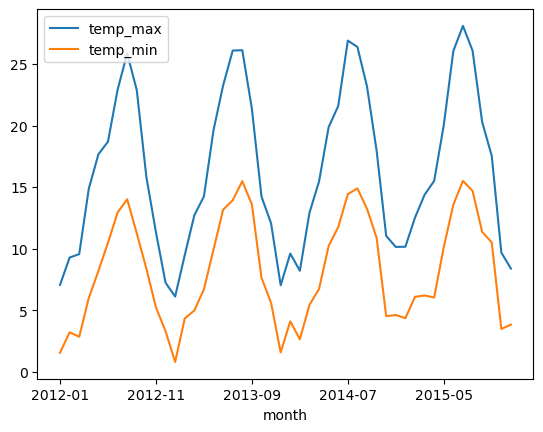

In [2]:
import pandas as pd
import matplotlib
df = pd.read_csv("data/weather.csv")
print(type(df))
print(df.shape)
print(df.index)
print(df.columns)
print(df.dtypes)
print("*"*50)

print(df.head())
print(df.tail(10))

df_date_series = df["date"]
print(df_date_series)
print(type(df_date_series))
df_date_dataFrame = df[["date"]]
print(type(df_date_dataFrame))

df[["date","temp_max","temp_min"]]
print(type(df.loc[1]))
df.loc[1] #一个的话就是series
df.loc[[1,10,100]]
df.iloc[0]
df.iloc[-1]

df.loc[1,"precipitation"]
df.loc[:,"precipitation"]
df.iloc[:,[3,5,-1]]
df.iloc[:10, 2:6] #列位置为2 3 4 5
df.loc[:10, ["date","precipitation","temp_max","temp_min"]]
print("*"*50)
# 分组聚合计算
print(type(pd.to_datetime(df["date"])))
df["month"] = pd.to_datetime(df["date"]).dt.to_period("M").astype(str)
df_groupby_date = df.groupby("month") #按month分组 返回分组对象
month_temp = df_groupby_date[["temp_max","temp_min"]] #从分组对象中选择特定的列
month_temp_mean = month_temp.mean()#对每个列求平均值
print(month_temp_mean)
#以上代码写在一起
month_temp_mean = df.groupby("month")[["temp_max", "temp_min"]].mean()
print(month_temp_mean)
#统计每个月不用天气状况的数量
df.groupby("month")["weather"].nunique()
#默认折线图
month_temp_mean = df.groupby("month")[["temp_max", "temp_min"]].mean().plot()
df.describe()
df.describe().T #行列转置
#inlucde 指定统计哪些
df.describe(include="all")
df.describe(include=["float64"]) #只统计数据类型为float64的列

In [96]:
#常用排序方法
import pandas as pd
df = pd.read_csv("data/weather.csv")
#温度最大前30
df.nlargest(30,"temp_max")
#温度最大前30中最低的5天
df.nlargest(30,"temp_max").nsmallest(5,"temp_min")
#每年最高温度
df["year"] = pd.to_datetime(df["date"]).dt.to_period("Y").astype(str)
year_temp_max = df.groupby("year")["temp_max"].max()
print("*"*50)
print(year_temp_max)
#按列升序或降序
df_sort = df.sort_values(["year","temp_max"],ascending=[True,False])
#按列去重
df_sort.drop_duplicates(subset="year")

**************************************************
year
2012    34.4
2013    33.9
2014    35.6
2015    35.0
Name: temp_max, dtype: float64


,date,precipitation,temp_max,temp_min,wind,weather,year
228,2012-08-16,0.0,34.4,18.3,2.8,sun,2012
546,2013-06-30,0.0,33.9,17.2,2.5,sun,2013
953,2014-08-11,0.5,35.6,17.8,2.6,rain,2014
1295,2015-07-19,0.0,35.0,17.2,3.3,sun,2015


### 简单数据分析练习

   employee_id first_name last_name     email  phone_number   job_id   salary  \
0          100     Steven      King     SKING  515.123.4567  AD_PRES  24000.0   
1          101      N_ann   Kochhar  NKOCHHAR  515.123.4568    AD_VP  17000.0   
2          102        Lex   De Haan   LDEHAAN  515.123.4569    AD_VP  17000.0   
3          103  Alexander    Hunold   AHUNOLD  590.423.4567  IT_PROG   9000.0   
4          104      Bruce     Ernst    BERNST  590.423.4568  IT_PROG   6000.0   

   commission_pct  manager_id  department_id  
0             NaN         NaN           90.0  
1             NaN       100.0           90.0  
2             NaN       100.0           90.0  
3             NaN       102.0           60.0  
4             NaN       103.0           60.0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 107 entries, 0 to 106
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   employee_id     107 non-null   

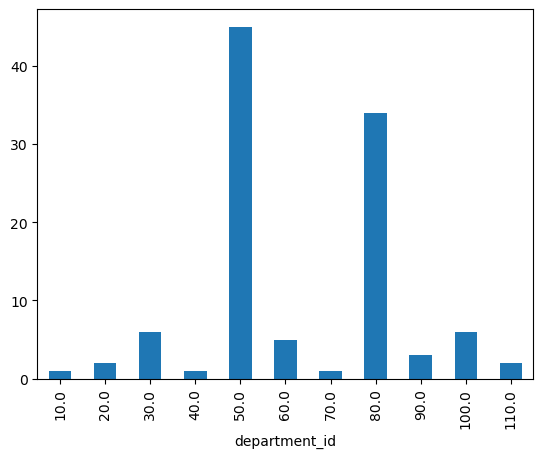

In [129]:
import pandas as pd
df = pd.read_csv("data/employees.csv")
#查看数据
print(df.head())
print(df.info())
print(df.describe()) #统计信息
print(df.shape)
#找出薪资最高最低员工
print("*"*50)
print(df["salary"].min())
print(type(df["salary"].min()))
df_min_emp = df[df["salary"] == df["salary"].min()]
print(df["salary"] == df["salary"].min())
print(df.loc[df["salary"] == df["salary"].min()])
print(df.loc[df["salary"] == df["salary"].max()])
print(df.sort_values("salary").head(1)) #使用排序方式找到薪资最低员工
print("*"*50)
print(df.sort_values("salary",ascending=False).head(1)) #使用排序方式找到薪资最高员工
print("*"*50)

#薪资前10
print(df.nlargest(10,"salary"))
#查看所有部门id
print(df["department_id"].unique())
#查看每个部门员工数量
print(df.groupby("department_id")["employee_id"].count().rename("employee_count"))
#绘图
df.groupby("department_id")["employee_id"].count().rename("employee_count").plot(kind="bar")
#薪资分布
print(df["salary"].mean())
print(df["salary"].std())
print(df["salary"].median())
#平均薪资最高的部门id
print(df.groupby("department_id")["salary"].mean().rename("salary_mean").index)
print(df.groupby("department_id")["salary"].mean().rename("salary_mean").dtype)
print(type(df.groupby("department_id")["salary"].mean().rename("salary_mean")))
print(df.groupby("department_id")["salary"].mean().rename("salary_mean").nlargest(1))

### pandas的数据组合函数

In [192]:
import pandas as pd

#concat
#Series和Series
#按行连接
s1 = pd.Series(["A", "B"], index=[1, 2])
s2 = pd.Series(["D", "E"], index=[4, 5])
s3 = pd.Series(["G", "H"], index=[7, 8])
s4 = pd.concat([s1, s2, s3])
print(s4)

#按列连接
print(pd.concat([s1, s2, s3],axis=1))

print("*"*100)
#DataFrame和Series
df1 = pd.DataFrame(data = {"a":[1,2], "b":[4,5]}, index=[1,2])
s1 = pd.Series(data = [7,10], index=[1, 2],name="a")
#按行连接
pd_row = pd.concat([df1, s1])
#按列连接
pd_col = pd.concat([df1, s1],axis=1)
print(pd_col)
# print(pd_row.loc[[1,2]])
# print(pd_row.iloc[[0,1,3]]) #定义了行index 还是会有隐式的

print("*"*100)
#DataFrame和DataFrame
df1 = pd.DataFrame(data = {"a":[1,2], "b":[4,5]}, index=[1,2])
df2 = pd.DataFrame(data = {"a":[7,8], "b":[10,11]}, index=[1,2])
#按行
pd.concat([df1, df2])
#按列
pd.concat([df1, df2],axis=1)

#重置索引
pd.concat([df1, df2],ignore_index=True)

#类似join
df1 = pd.DataFrame(data = {"a":[1,2], "b":[4,5]}, index=[1,2])
df2 = pd.DataFrame(data = {"b":[7,8], "c":[10,11]}, index=[2,3])
pd.concat([df1, df2])

pd.concat([df1, df2],join="inner")

#merge

#一对一
df1 = pd.DataFrame({"employee": ["Bob", "Jake", "Lisa", "Sue"], "group": ["Accounting", "Engineering", "Engineering", "HR"]})
df2 = pd.DataFrame({"employee":["Lisa","Bob","Jake","Sue"],"hire_date":[2004,2008,2012,2014]})
print(df1)
print(df2)
#通过相同字段名进行关联
df3 = pd.merge(df1, df2)
print(df3)

#多对一
df1 = pd.DataFrame(
  {"employee": ["Bob", "Jake", "Lisa", "Sue"], "group": ["Accounting", "Engineering", "Engineering", "HR"]}
)
df2 = pd.DataFrame({"group": ["Accounting", "Engineering", "HR"], "supervisor": ["Carly", "Guido", "Steve"]})
print(df1)
print(df2)
df3 = pd.merge(df1, df2)
print(df3)

#多对多
df1 = pd.DataFrame(
  {"employee": ["Bob", "Jake", "Lisa", "Sue"], "group": ["Accounting", "Engineering", "Engineering", "HR"]}
)
df2 = pd.DataFrame(
  {
    "group": ["Accounting", "Accounting", "Engineering", "Engineering", "HR", "HR"],
    "skills": ["math", "spreadsheets", "coding", "linux", "spreadsheets", "organization"],
  }
)
print(df1)
print(df2)
print("多对多")
print(pd.merge(df1,df2))

#设置合并键和索引
df1 = pd.DataFrame(
  {"employee": ["Bob", "Jake", "Lisa", "Sue"], "group": ["Accounting", "Engineering", "Engineering", "HR"]}
)
df2 = pd.DataFrame({"employee": ["Lisa", "Bob", "Jake", "Sue"], "hire_date": [2004, 2008, 2012, 2014]})
print(df1)
print(df2)
print(pd.merge(df1,df2,on="employee"))

df1 = pd.DataFrame(
  {"employee": ["Bob", "Jake", "Lisa", "Sue"], "group": ["Accounting", "Engineering", "Engineering", "HR"]}
)
df2 = pd.DataFrame({"name": ["Lisa", "Bob", "Jake", "Sue"], "hire_date": [2004, 2008, 2012, 2014]})
print(df1)
print(df2)
print(pd.merge(df1,df2,left_on="employee",right_on="name"))

df1 = pd.DataFrame(
  {"employee": ["Bob", "Jake", "Lisa", "Sue"], "group": ["Accounting", "Engineering", "Engineering", "HR"]}
)
df2 = pd.DataFrame({"employee": ["Lisa", "Bob", "Jake", "Sue"], "hire_date": [2004, 2008, 2012, 2014]})
df1.set_index("employee", inplace=True)
df2.set_index("employee", inplace=True)
print(df1)
print(df2)
print(pd.merge(df1,df2,left_index=True,right_index=True))

#DataFrame 实现了join方法 按照索引进行数据合并
df1 = pd.DataFrame({
  'key': ['A', 'B', 'C'],
  'value1': [1, 2, 3]
})

df2 = pd.DataFrame({
  'key': ['B', 'C', 'D'],
  'value2': [4, 5, 6]
})
df1.join(df2,lsuffix="_left",rsuffix="_right")

#设置数据连接的集合操作规则
df1 = pd.DataFrame({"name": ["Peter", "Paul", "Mary"], "food": ["fish", "beans", "bread"]}, columns=["name", "food"])
df2 = pd.DataFrame({"name": ["Mary", "Joseph"], "drink": ["wine", "beer"]}, columns=["name", "drink"])
print(df1)
print(df2)
print(pd.merge(df1,df2))
print(pd.merge(df1,df2,how="outer"))
print(pd.merge(df1,df2,how="left"))

#重复列名处理
df1 = pd.DataFrame({"name": ["Bob", "Jake", "Lisa", "Sue"], "rank": [1, 2, 3, 4]})
df2 = pd.DataFrame({"name": ["Bob", "Jake", "Lisa", "Sue"], "rank": [3, 1, 4, 2]})
print(df1)
print(df2)
print(pd.merge(df1,df2,on="name")) #不指定后缀名
print(pd.merge(df1,df2,on="name", suffixes=("_df1","_df2"))) #通过suffixes指定后缀名

1    A
2    B
4    D
5    E
7    G
8    H
dtype: object
     0    1    2
1    A  NaN  NaN
2    B  NaN  NaN
4  NaN    D  NaN
5  NaN    E  NaN
7  NaN  NaN    G
8  NaN  NaN    H
****************************************************************************************************
   a  b   a
1  1  4   7
2  2  5  10
****************************************************************************************************
  employee        group
0      Bob   Accounting
1     Jake  Engineering
2     Lisa  Engineering
3      Sue           HR
  employee  hire_date
0     Lisa       2004
1      Bob       2008
2     Jake       2012
3      Sue       2014
  employee        group  hire_date
0      Bob   Accounting       2008
1     Jake  Engineering       2012
2     Lisa  Engineering       2004
3      Sue           HR       2014
  employee        group
0      Bob   Accounting
1     Jake  Engineering
2     Lisa  Engineering
3      Sue           HR
         group supervisor
0   Accounting      Carly
1  Enginee

### 缺失值处理

In [199]:
import pandas as pd
import numpy as np
s = pd.Series([np.nan,None,pd.NA])
print(s)
print(s.isnull())
print(s.notnull())

0     NaN
1    None
2    <NA>
dtype: object
0    True
1    True
2    True
dtype: bool
0    False
1    False
2    False
dtype: bool


In [204]:
#包含缺失
df = pd.read_csv("data/weather_withna.csv")
print(df.tail(5))
#keep_default_na 参数设置讲空白值设置为缺失值
df = pd.read_csv("data/weather_withna.csv",keep_default_na=False)
print(df.tail(5))
#na_values 设定值替代为缺失值
df = pd.read_csv("data/weather_withna.csv",na_values=["2015-12-31"])
print(df.tail(5))

            date  precipitation  temp_max  temp_min  wind weather
1456  2015-12-27            NaN       NaN       NaN   NaN     NaN
1457  2015-12-28            NaN       NaN       NaN   NaN     NaN
1458  2015-12-29            NaN       NaN       NaN   NaN     NaN
1459  2015-12-30            NaN       NaN       NaN   NaN     NaN
1460  2015-12-31           20.6      12.2       5.0   3.8    rain
            date precipitation temp_max temp_min wind weather
1456  2015-12-27                                             
1457  2015-12-28                                             
1458  2015-12-29                                             
1459  2015-12-30                                             
1460  2015-12-31          20.6     12.2      5.0  3.8    rain
            date  precipitation  temp_max  temp_min  wind weather
1456  2015-12-27            NaN       NaN       NaN   NaN     NaN
1457  2015-12-28            NaN       NaN       NaN   NaN     NaN
1458  2015-12-29            NaN   

date               0
precipitation    303
temp_max         303
temp_min         303
wind             303
weather          303
dtype: int64


<Axes: >

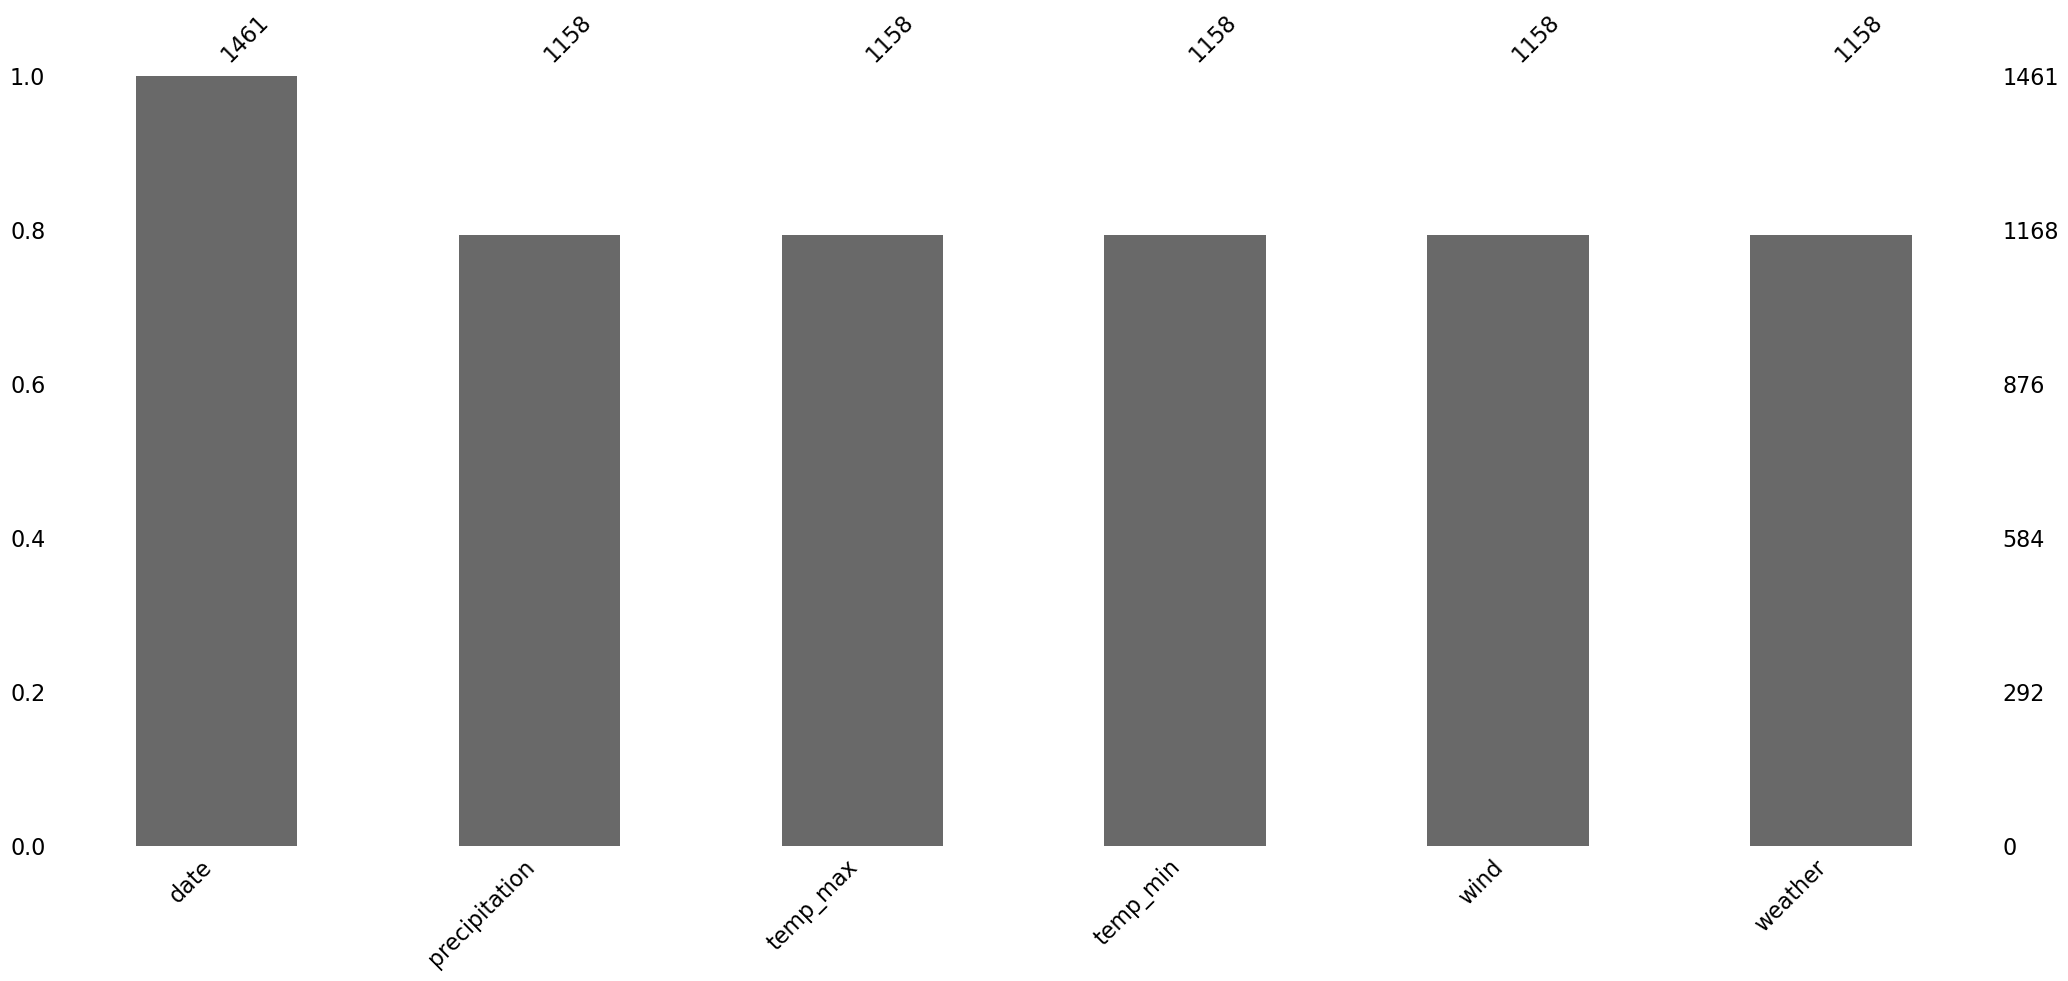

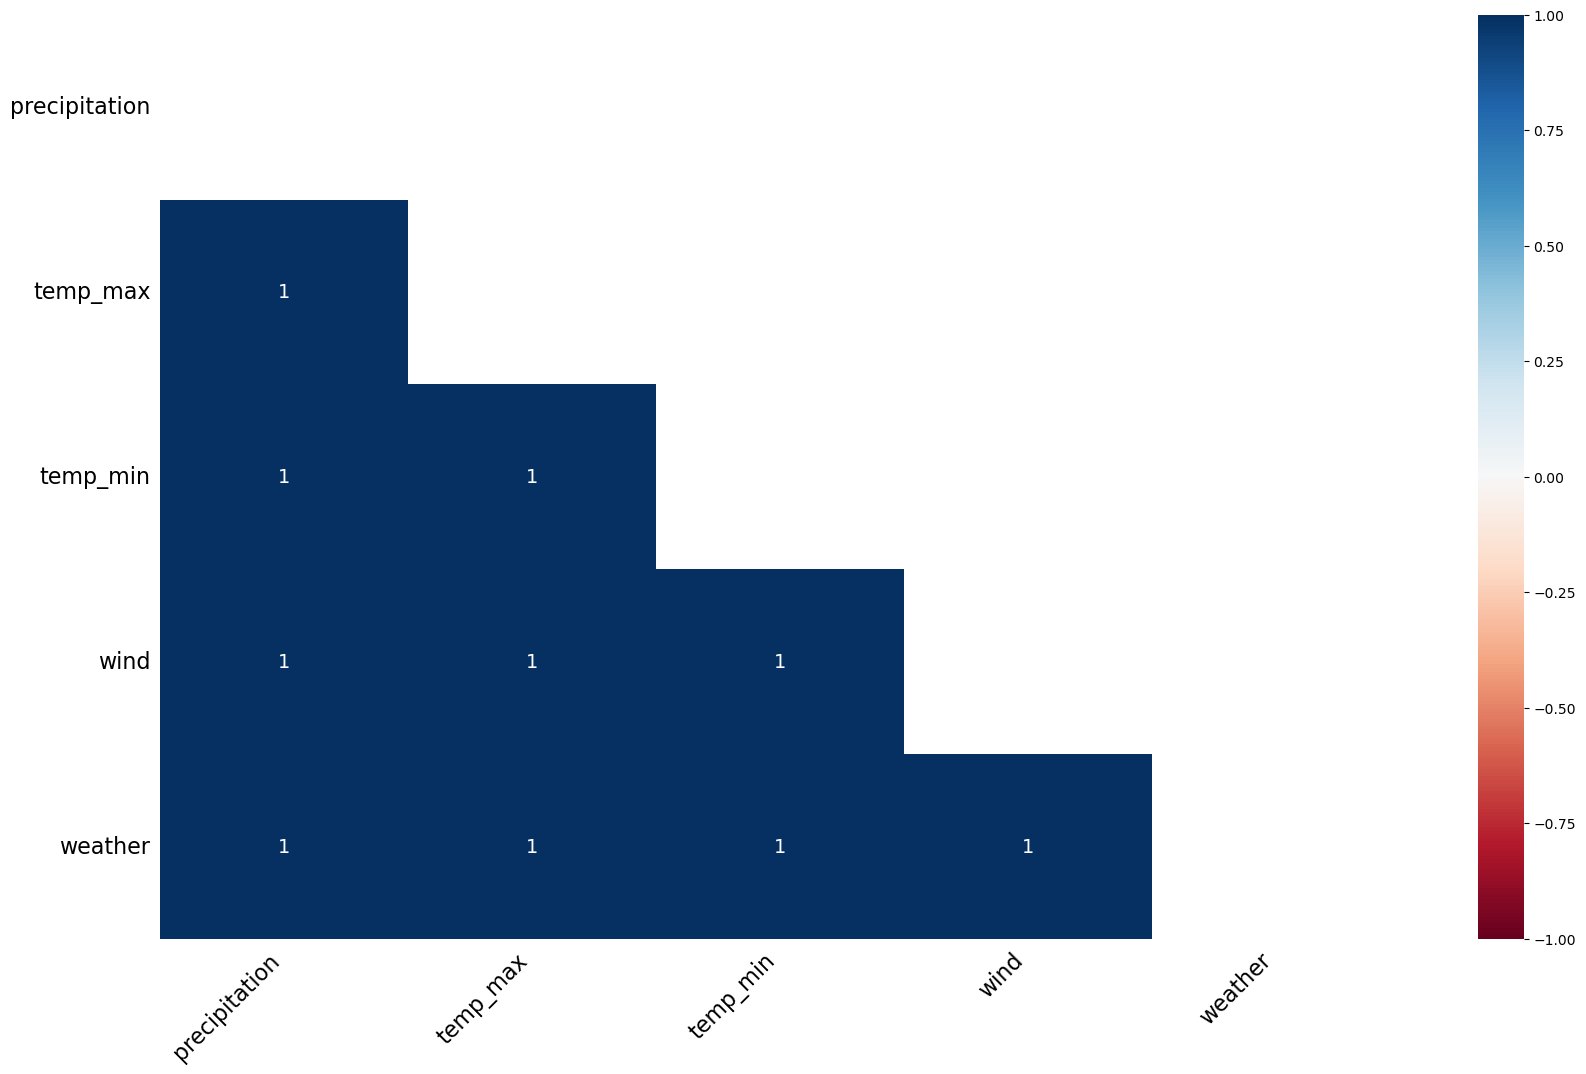

In [5]:
#查看缺失
import missingno as msno
import pandas as pd
df = pd.read_csv("data/weather_withna.csv")
print(df.isnull().sum())

df = pd.read_csv("data/weather_withna.csv")
msno.bar(df)
msno.heatmap(df)

In [17]:
# 剔除缺失
s = pd.Series([1,None,pd.NA])
print(s)
print(s.dropna())

df = pd.DataFrame([[1,pd.NA,2],[2,3,5],[pd.NA,4,6]])
print(df)
print(df.dropna())
print(df.dropna(axis=1))

#删除所有都是缺失值的行或列，设置缺失值的数量阈值
df = pd.DataFrame([[1, pd.NA, 2], [pd.NA, pd.NA, 5], [pd.NA, pd.NA, pd.NA]])
print(df)
print(df.dropna(how="all"))
#至少有两个不是缺失值保留这行
print(df.dropna(thresh=2))

#通过特指对某一列的缺失值进行删除
print(df)
print(df.dropna(subset=[0])) #如果0列有缺失值则删除这一行

0       1
1    None
2    <NA>
dtype: object
0    1
dtype: object
      0     1  2
0     1  <NA>  2
1     2     3  5
2  <NA>     4  6
   0  1  2
1  2  3  5
   2
0  2
1  5
2  6
      0     1     2
0     1  <NA>     2
1  <NA>  <NA>     5
2  <NA>  <NA>  <NA>
      0     1  2
0     1  <NA>  2
1  <NA>  <NA>  5
   0     1  2
0  1  <NA>  2
      0     1     2
0     1  <NA>     2
1  <NA>  <NA>     5
2  <NA>  <NA>  <NA>
   0     1  2
0  1  <NA>  2


In [2]:
#填充缺失值
#使用固定值填充
import numpy as np
import pandas as pd
df = pd.read_csv("data/weather_withna.csv")
print(df.tail())
print(df.fillna(0).tail())
print(df.fillna({"temp_max":60,"temp_min":-60}).tail())
#使用统计值填充
print(df.fillna(df[["precipitation","temp_max","temp_min","wind"]].mean()).tail())
#使用前后有效值填充
print(df.ffill().tail()) #使用前面有效值填充
print(df.bfill().tail()) #使用后面有效值填充
#通过线性差插值填充
s = pd.Series([1,np.nan,3,4,np.nan,6])
print(s)
s_interpolated = s.interpolate()
print(s_interpolated)

            date  precipitation  temp_max  temp_min  wind weather
1456  2015-12-27            NaN       NaN       NaN   NaN     NaN
1457  2015-12-28            NaN       NaN       NaN   NaN     NaN
1458  2015-12-29            NaN       NaN       NaN   NaN     NaN
1459  2015-12-30            NaN       NaN       NaN   NaN     NaN
1460  2015-12-31           20.6      12.2       5.0   3.8    rain
            date  precipitation  temp_max  temp_min  wind weather
1456  2015-12-27            0.0       0.0       0.0   0.0       0
1457  2015-12-28            0.0       0.0       0.0   0.0       0
1458  2015-12-29            0.0       0.0       0.0   0.0       0
1459  2015-12-30            0.0       0.0       0.0   0.0       0
1460  2015-12-31           20.6      12.2       5.0   3.8    rain
            date  precipitation  temp_max  temp_min  wind weather
1456  2015-12-27            NaN      60.0     -60.0   NaN     NaN
1457  2015-12-28            NaN      60.0     -60.0   NaN     NaN
1458  2015

### Series使用apply()

In [6]:
import pandas as pd
def func(item):
    return item * 20
s = pd.Series([10,20,30])
s.apply(func)
s.apply(lambda item: item * 10)

def func1(item,p1):
    return item * p1
s.apply(func1,p1=3)

0    30
1    60
2    90
dtype: int64

### DataFrame使用apply()

In [11]:
import numpy as np
import pandas as pd
def func(item):
    print(type(item))
    res = item.sum()
    return 100 if res < 100 else res

df = pd.DataFrame({"a":[10,20,30],"b":[40,50,60]})
# df.sum() #每个series
# df.apply(func)
df.apply(func,axis = 1)

<class 'pandas.core.series.Series'>
<class 'pandas.core.series.Series'>
<class 'pandas.core.series.Series'>


0    100
1    100
2    100
dtype: int64

In [13]:
import pandas as pd
def func(s):
    return s["a"] / s["b"]

df = pd.DataFrame({"a":[10,20,30],"b":[40,50,60]})
df.apply(func,axis = 1)

0    0.25
1    0.40
2    0.50
dtype: float64

In [20]:
#标量计算转为向量计算
import numpy as np
@np.vectorize
def f(x,y):
    if y == 0:
        return np.nan
    return x / y

# s = pd.Series([10,20,30])
# s == 0

df = pd.DataFrame({"a":[10,20,30],"b":[40,0,60]})
# f(10,20)
f(df["a"],df["b"])
# f_vec = np.vectorize(f)
# f_vec(df["a"],df["b"])




array([0.25,  nan, 0.5 ])

### DataFrameGroupBy

In [43]:
import pandas as pd
#读取员工数据
df = pd.read_csv(r"/Users/blucechen/Documents/尚硅谷大模型/data/employees.csv")
df

#按照部门id进行分组
groupby_df = df.groupby("department_id")
groupby_df

#查看分组
groupby_df.groups #通过groups属性查看分组结果，字典的键是分组的标签，值是属于该组的所有索引的列表
groupby_df.get_group(30)

#按列取值
groupby_df[["salary"]]
groupby_df["salary"]

#按组迭代
for dept_id,group in groupby_df:
    print(f"当前组为{dept_id},组里的数据情况{group.shape}")
    print(group.iloc[:,0:3])
    print("------------------------")

#按多字段分组
salary_mean = df.groupby(["department_id","job_id"],as_index=False)[["salary","commission_pct"]].mean()
salary_mean.info()
salary_mean.reset_index()
salary_mean

#cut
df = pd.read_csv(r"/Users/blucechen/Documents/尚硅谷大模型/data/employees.csv")
df

pd.cut(df.iloc[9:16]["salary"],3)
pd.cut(df.iloc[9:16]["salary"],[0,10000,20000])
pd.cut(df.iloc[9:16]["salary"],3,labels=["low","medium","high"])

当前组为10.0,组里的数据情况(1, 10)
     employee_id first_name last_name
100          200   Jennifer    Whalen
------------------------
当前组为20.0,组里的数据情况(2, 10)
     employee_id first_name  last_name
101          201    Michael  Hartstein
102          202        Pat        Fay
------------------------
当前组为30.0,组里的数据情况(6, 10)
    employee_id first_name   last_name
14          114        Den    Raphaely
15          115  Alexander        Khoo
16          116     Shelli       Baida
17          117      Sigal      Tobias
18          118        Guy      Himuro
19          119      Karen  Colmenares
------------------------
当前组为40.0,组里的数据情况(1, 10)
     employee_id first_name last_name
103          203      Susan    Mavris
------------------------
当前组为50.0,组里的数据情况(45, 10)
    employee_id first_name    last_name
20          120    Matthew        Weiss
21          121       Adam        Fripp
22          122      Payam     Kaufling
23          123     Shanta      Vollman
24          124      Kevin      Mourg

9       high
10    medium
11    medium
12    medium
13    medium
14      high
15       low
Name: salary, dtype: category
Categories (3, object): ['low' < 'medium' < 'high']